<a href="https://colab.research.google.com/github/srigstinahf/RevoU_Project/blob/main/Projek_RevoU_Data_Analyst.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_excel("Dataset Case Study Python.xlsx")

df.head()

,event_id,user_id,session_id,event_type,event_timestamp,product_id,country,device,channel
0,9bd8725f-5722-41b7-8d95-a5dafec33a56,482c0ae4-ac6c-4eb3-91fe-b0e63c1c2a5d,98b232db-5bec-41d8-88e1-5d2e98899e29,product_view,2025-09-22 16:35:26.996,P1208,US,IOS,paid_search
1,f6dc704c-a88c-4668-b89d-e6b08e7e02d4,ff6c808d-fa75-4202-801f-a076299a2c0f,d4832af2-0aad-489c-8eb6-22d243f5f5c4,page_view,2025-06-04 21:55:03.996,NaN,ID,android,referral
2,abb69be8-df83-420b-92f7-149d29a6d32f,78ea2c10-e824-4b3c-b74b-cdb0cbab0610,1f6c5b12-6c79-4b29-bae6-878804723e55,page_view,2025-06-24 02:02:50.996,NaN,AU,IOS,paid_search
3,76fd2399-0f80-4184-8802-90dac9bf52d3,9c63419c-b3dc-44a6-b8a5-a438e82afee8,ed1c4ded-cf67-463e-b94f-4cebcf62d827,page_view,2025-06-05 12:35:32.996,NaN,VN,IOS,organic
4,26dcc5fa-334c-420c-be1e-a40eb4b9efac,f9aee3bb-2ba4-4bb3-9eec-44ba4664f93b,9a469fb9-6cf4-4818-b0a6-7302b0bd665a,product_view,2025-07-02 12:19:22.996,P1315,ID,desktop,social


In [4]:
# Informasi dataset
print("DATASET INFORMATION")
print("Jumlah baris dan kolom:", df.shape)

print("\nDATA TYPES")
print(df.info())

print("\nMISSING VALUES")
print(df.isnull().sum())

print("\nDUPLICATE DATA")
print("Jumlah duplikat:", df.duplicated().sum())

print("\nUNIQUE VALUES")
for col in df.columns:
    print(f"{col}: {df[col].nunique()}")

print("\nEVENT TYPE")
print(df["event_type"].value_counts())

print("\nCOUNTRY")
print(df["country"].value_counts())

print("\nDEVICE")
print(df["device"].value_counts())

print("\nCHANNEL")
print(df["channel"].value_counts(dropna=False))


DATASET INFORMATION
Jumlah baris dan kolom: (10000, 9)

DATA TYPES
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   event_id         10000 non-null  object        
 1   user_id          10000 non-null  object        
 2   session_id       10000 non-null  object        
 3   event_type       10000 non-null  object        
 4   event_timestamp  10000 non-null  datetime64[ns]
 5   product_id       4463 non-null   object        
 6   country          10000 non-null  object        
 7   device           10000 non-null  object        
 8   channel          9900 non-null   object        
dtypes: datetime64[ns](1), object(8)
memory usage: 703.3+ KB
None

MISSING VALUES
event_id              0
user_id               0
session_id            0
event_type            0
event_timestamp       0
product_id         5537
country          

In [5]:
df_clean = df.copy()

df_clean["event_timestamp"] = pd.to_datetime(
    df_clean["event_timestamp"],
    errors="coerce"
)

df_clean["device"] = (
    df_clean["device"]
    .str.strip()
    .str.lower()
)

df_clean["channel"] = (
    df_clean["channel"]
    .str.strip()
    .str.lower()
)

df_clean["event_type"] = (
    df_clean["event_type"]
    .str.strip()
    .str.lower()
)

# Memeriksa kembali missing values
print("Missing values setelah cleaning:")
print(df_clean.isnull().sum())

print("\nJumlah baris setelah cleaning:")
print(df_clean.shape)


Missing values setelah cleaning:
event_id              0
user_id               0
session_id            0
event_type            0
event_timestamp       0
product_id         5537
country               0
device                0
channel             100
dtype: int64

Jumlah baris setelah cleaning:
(10000, 9)


In [6]:
# Memeriksa kategori setelah cleaning
print("Device setelah cleaning:")
print(df_clean["device"].value_counts())

print("\nChannel setelah cleaning:")
print(df_clean["channel"].value_counts(dropna=False))


Device setelah cleaning:
device
android    4961
ios        4000
desktop    1039
Name: count, dtype: int64

Channel setelah cleaning:
channel
email          1707
direct         1646
paid_search    1646
referral       1645
organic        1629
social         1627
NaN             100
Name: count, dtype: int64


In [7]:
# Mengubah missing channel menjadi unknown
df_clean["channel"] = df_clean["channel"].fillna("unknown")

print("Missing values setelah final cleaning:")
print(df_clean.isnull().sum())

print("\nJumlah data:")
print(df_clean.shape)

print("\nDistribusi channel:")
print(df_clean["channel"].value_counts())


Missing values setelah final cleaning:
event_id              0
user_id               0
session_id            0
event_type            0
event_timestamp       0
product_id         5537
country               0
device                0
channel               0
dtype: int64

Jumlah data:
(10000, 9)

Distribusi channel:
channel
email          1707
direct         1646
paid_search    1646
referral       1645
organic        1629
social         1627
unknown         100
Name: count, dtype: int64


Question 1: Which country has the most active user in Q2 2025? Make visualization with comparisons of all countries.

In [8]:
# Filter data Q2 2025
q2_data = df_clean[
    (df_clean["event_timestamp"] >= "2025-04-01") &
    (df_clean["event_timestamp"] < "2025-07-01")
].copy()

print("Jumlah baris data Q2:", len(q2_data))

print("\nRentang tanggal:")
print(q2_data["event_timestamp"].min())
print(q2_data["event_timestamp"].max())


Jumlah baris data Q2: 5105

Rentang tanggal:
2025-04-01 00:05:29.996000
2025-06-30 23:13:10.996000


In [9]:
# Menghitung jumlah active user per negara
active_users_country = (
    q2_data.groupby("country")["user_id"]
    .nunique()
    .reset_index()
)

# Mengubah nama kolom
active_users_country.columns = [
    "Country",
    "Active Users"
]

# Mengurutkan dari tertinggi
active_users_country = (
    active_users_country
    .sort_values(
        by="Active Users",
        ascending=False
    )
    .reset_index(drop=True)
)

print(active_users_country)

  Country  Active Users
0      ID          1055
1      US           815
2      VN           485
3      PH           464
4      MY           460
5      SG           459
6      TH           236
7      AU           215


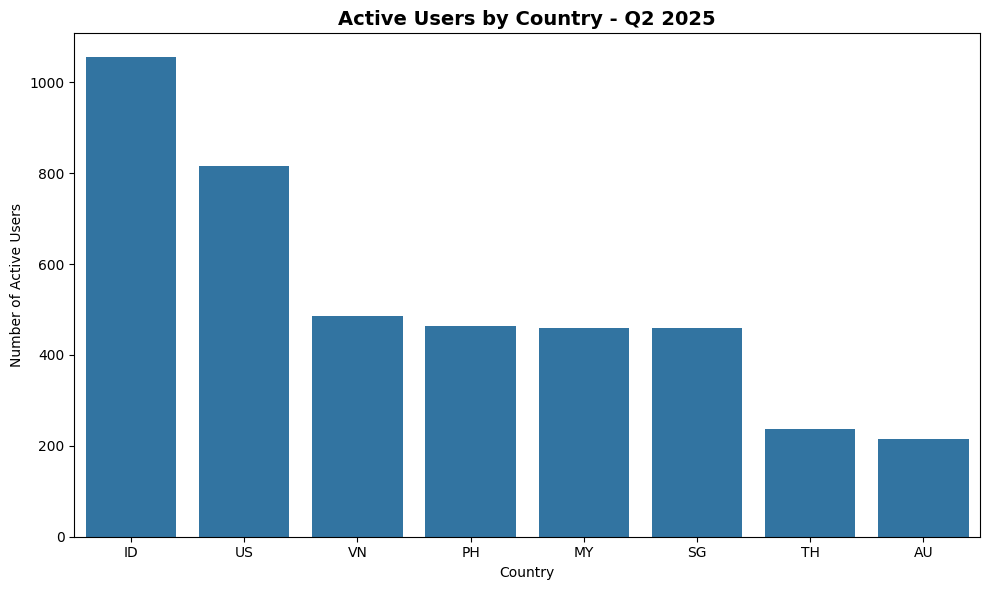

In [10]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=active_users_country,
    x="Country",
    y="Active Users"
)

plt.title(
    "Active Users by Country - Q2 2025",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Country")
plt.ylabel("Number of Active Users")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Question 2: How is the trend of Monthly Active User for each channel?

In [11]:
# Mengelompokkan berdasarkan bulan dan tahun
df_clean["month"] = (
    df_clean["event_timestamp"]
    .dt.to_period("M")
)


print(df_clean["month"].value_counts().sort_index())

month
2025-03     239
2025-04    1678
2025-05    1694
2025-06    1733
2025-07    1735
2025-08    1651
2025-09    1270
Freq: M, Name: count, dtype: int64


In [12]:
# Menghitung unique users berdasarkan bulan dan channel
mau = (
    df_clean.groupby(["month", "channel"])["user_id"]
    .nunique()
    .reset_index()
)

# Mengubah nama kolom
mau.columns = [
    "Month",
    "Channel",
    "Monthly Active Users"
]

# Menampilkan hasil
print(mau)

      Month      Channel  Monthly Active Users
0   2025-03       direct                    41
1   2025-03        email                    33
2   2025-03      organic                    34
3   2025-03  paid_search                    38
4   2025-03     referral                    50
5   2025-03       social                    40
6   2025-03      unknown                     2
7   2025-04       direct                   262
8   2025-04        email                   258
9   2025-04      organic                   260
10  2025-04  paid_search                   255
11  2025-04     referral                   244
12  2025-04       social                   276
13  2025-04      unknown                    15
14  2025-05       direct                   270
15  2025-05        email                   284
16  2025-05      organic                   251
17  2025-05  paid_search                   259
18  2025-05     referral                   244
19  2025-05       social                   268
20  2025-05  

In [13]:
mau_pivot = mau.pivot(
    index="Month",
    columns="Channel",
    values="Monthly Active Users"
).fillna(0)

print(mau_pivot)


Channel  direct  email  organic  paid_search  referral  social  unknown
Month                                                                  
2025-03      41     33       34           38        50      40        2
2025-04     262    258      260          255       244     276       15
2025-05     270    284      251          259       244     268       13
2025-06     271    263      259          258       289     262       15
2025-07     257    290      268          288       255     250       15
2025-08     250    248      249          251       292     240       20
2025-09     186    209      208          206       197     174       20


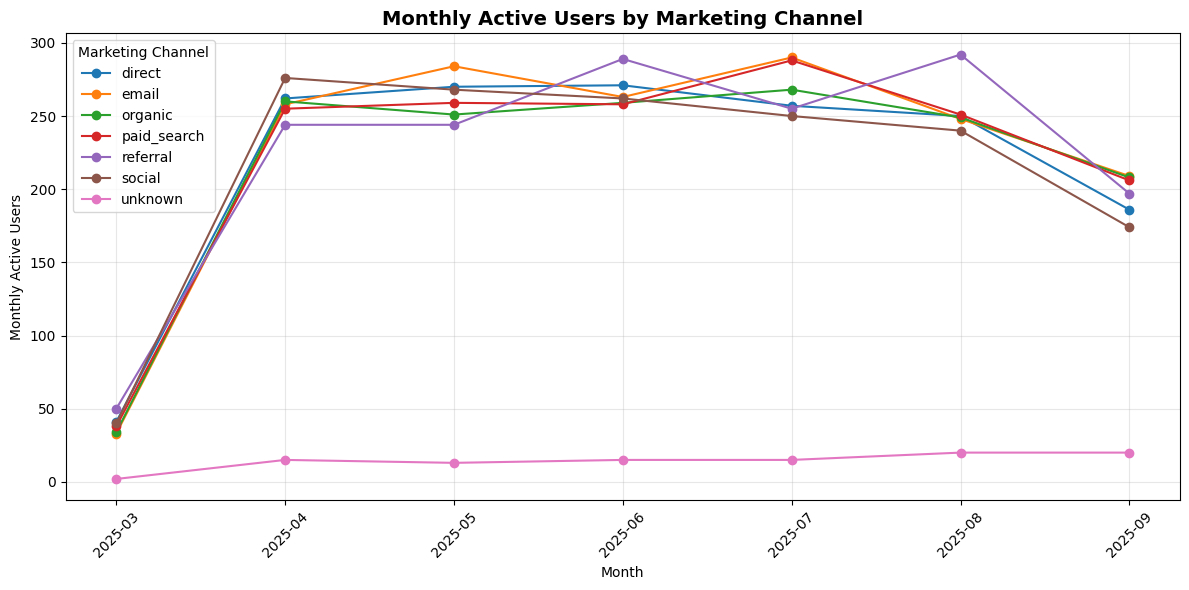

In [14]:
plt.figure(figsize=(12, 6))

for channel in mau_pivot.columns:
    plt.plot(
        mau_pivot.index.astype(str),
        mau_pivot[channel],
        marker="o",
        label=channel
    )

plt.title(
    "Monthly Active Users by Marketing Channel",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Month")
plt.ylabel("Monthly Active Users")

plt.xticks(rotation=45)
plt.legend(title="Marketing Channel")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


Question 3: Which devices is used the most often (by session)?

In [15]:
# Menghitung jumlah session unik berdasarkan device
device_usage = (
    df_clean.groupby("device")["session_id"]
    .nunique()
    .reset_index()
)

# Mengubah nama kolom
device_usage.columns = [
    "Device",
    "Total Sessions"
]

# Mengurutkan berdasarkan jumlah session
device_usage = device_usage.sort_values(
    by="Total Sessions",
    ascending=False
).reset_index(drop=True)

print(device_usage)


    Device  Total Sessions
0  android            4961
1      ios            4000
2  desktop            1039


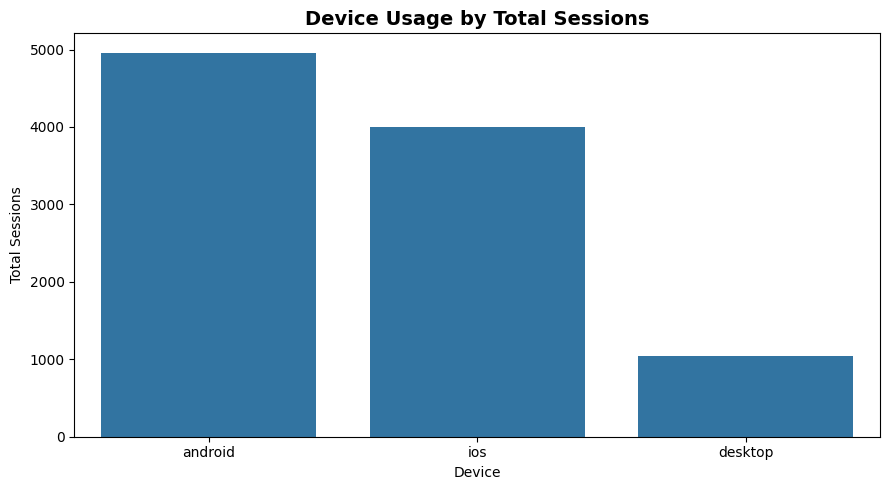

In [16]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=device_usage,
    x="Device",
    y="Total Sessions"
)

plt.title(
    "Device Usage by Total Sessions",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Device")
plt.ylabel("Total Sessions")

plt.tight_layout()
plt.show()


In [17]:
# Menghitung persentase penggunaan perangkat
device_usage["Percentage"] = (
    device_usage["Total Sessions"] /
    device_usage["Total Sessions"].sum()
) * 100

print(device_usage)


    Device  Total Sessions  Percentage
0  android            4961       49.61
1      ios            4000       40.00
2  desktop            1039       10.39


Question 4: What percentage of users who search end up adding to carts (ATC) on the same day?

In [18]:
# Mengambil aktivitas Search
search = df_clean[
    df_clean["event_type"] == "search"
].copy()

# Mengambil aktivitas Add to Cart
atc = df_clean[
    df_clean["event_type"] == "add_to_cart"
].copy()

print("Total Search Events:", len(search))
print("Total ATC Events:", len(atc))

print("\nUnique Search Users:", search["user_id"].nunique())
print("Unique ATC Users:", atc["user_id"].nunique())


Total Search Events: 945
Total ATC Events: 970

Unique Search Users: 750
Unique ATC Users: 773


In [19]:
# Membuat kolom tanggal
search["date"] = search["event_timestamp"].dt.date
atc["date"] = atc["event_timestamp"].dt.date

# Menggabungkan data berdasarkan user_id dan tanggal
merged = search.merge(
    atc,
    on=["user_id", "date"],
    suffixes=("_search", "_atc")
)

print("Total pasangan Search dan ATC:", len(merged))


Total pasangan Search dan ATC: 2


In [20]:
# Memastikan waktu ATC lebih besar daripada waktu Search
valid_atc = merged[
    merged["event_timestamp_atc"] >
    merged["event_timestamp_search"]
].copy()

print("Total pasangan valid:", len(valid_atc))

# Menghitung pengguna unik yang berhasil melakukan ATC
converted_users = valid_atc["user_id"].nunique()

print("Converted Users:", converted_users)


Total pasangan valid: 1
Converted Users: 1


In [21]:
# Menghitung total pengguna unik yang melakukan Search
total_search_users = search["user_id"].nunique()

# Menghitung conversion rate
conversion_rate = (
    converted_users / total_search_users
) * 100

print("Total Search Users:", total_search_users)
print("Converted Users:", converted_users)
print(f"Conversion Rate: {conversion_rate:.2f}%")


Total Search Users: 750
Converted Users: 1
Conversion Rate: 0.13%


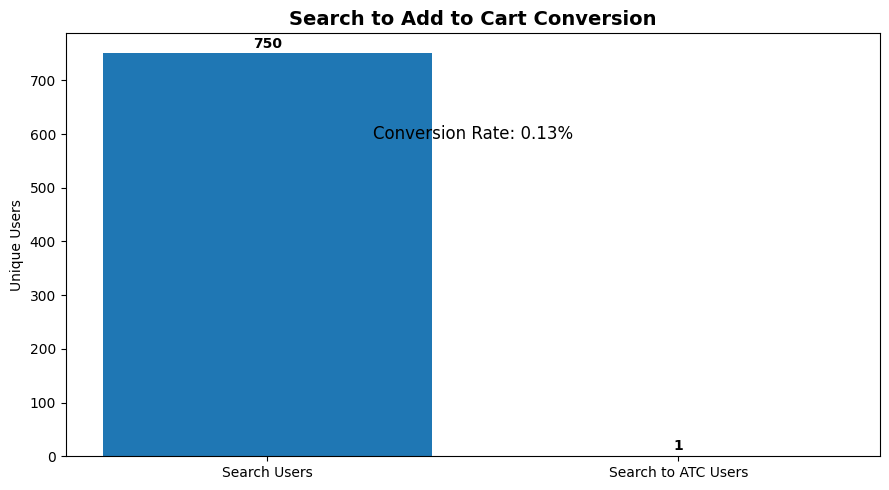

In [27]:
plt.figure(figsize=(9, 5))

bars = plt.bar(
    ["Search Users", "Search to ATC Users"],
    [total_search_users, converted_users]
)

plt.title(
    "Search to Add to Cart Conversion",
    fontsize=14,
    fontweight="bold"
)

plt.ylabel("Unique Users")

# Menambahkan label angka
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 10,
        f"{int(height)}",
        ha="center",
        fontweight="bold"
    )

plt.text(
    0.5, 0.75,
    f"Conversion Rate: {conversion_rate:.2f}%",
    transform=plt.gca().transAxes,
    ha="center",
    fontsize=12
)

plt.tight_layout()
plt.show()
